In [1]:
# Code from Milestone 2 to carry over
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


DATA_PATH = Path("PL_team_matches.csv")
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df_home = df[df["HomeAway"] == "Home"].copy()


df_home = df_home.sort_values(["Team", "Date"]).reset_index(drop=True)

def add_last5_home(g):
    g = g.sort_values("Date").copy()
    for stat in ["Goals", "HS", "HST"]:
        g[f"{stat}_avg5"] = g[stat].shift(1).rolling(5, min_periods=1).mean()
    return g

df_home = (
    df_home.groupby("Team", group_keys=False)
           .apply(add_last5_home)
           .reset_index(drop=True))

df_home["Target"] = (df_home["Goals"] >= 2).astype(int)

model_cols = ["MatchID", "Date", "Time", "Team", "Opponent", "HomeAway",
              "Target", "Goals_avg5", "HS_avg5", "HST_avg5"]
df_model = df_home[model_cols].copy()


train_end = "2024-08-01"
val_end = "2025-08-01"

train = df_model[df_model["Date"] < train_end]
validation = df_model[(df_model["Date"] >= train_end) & (df_model["Date"] < val_end)]
test = df_model[df_model["Date"] >= val_end]

feature_cols = ["Goals_avg5", "HS_avg5", "HST_avg5"]
X_train, y_train = train[feature_cols], train["Target"]
X_val,   y_val   = validation[feature_cols], validation["Target"]
X_test,  y_test  = test[feature_cols], test["Target"]

In [2]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {"Dummy": make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="most_frequent")),
    
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
    
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                     RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=5,
                     oob_score=True, n_jobs=-1, random_state=42)),
    
    "k-NN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), 
            KNeighborsClassifier(n_neighbors=7, weights="distance")),
          
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"),
                         GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=2,
                         subsample=0.8, random_state=42))}

In [3]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate


train_sorted = train.sort_values(["Date", "Time"])
X_cv = train_sorted[feature_cols]
y_cv = train_sorted["Target"]

cv = TimeSeriesSplit(n_splits=5)

rows = []
for name, model in models.items():
    results = cross_validate(
        model, X_cv, y_cv, cv=cv,
        scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"},
        return_train_score=True)
    
    rows.append({"Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "F1": results["test_f1"].mean(),
        "ROC-AUC mean": results["test_roc_auc"].mean(),
        "ROC-AUC std": results["test_roc_auc"].std(),
        "Fit time (s)": results["fit_time"].mean(),
        "Predict time (s)": results["score_time"].mean(),})

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results

,Accuracy,F1,ROC-AUC mean,ROC-AUC std,Fit time (s),Predict time (s)
Model,,,,,,
Dummy,0.519,0.000,0.500,0.000,0.010,0.018
Logistic Regression,0.593,0.446,0.601,0.030,0.037,0.020
Random Forest,0.576,0.473,0.583,0.050,2.525,0.473
k-NN,0.534,0.472,0.540,0.045,0.012,0.024
Gradient Boosting,0.562,0.474,0.569,0.039,0.545,0.025


In [4]:
# Using time-ordered cross-validation on the 2021/22-2023/24 seasons, all four learned models beat the dummy baseline
# (ROC-AUC 0.500) but only by small margins. Logistic regression performed best (ROC-AUC 0.601, accuracy 0.593)
# and was the most stable across folds (std 0.030). Random forest (0.583) and gradient boosting (0.569) came close, 
# while k-NN (0.540) was barely above the baseline. The more complex models did not beat the simple one, 
# and the random forest was far slower to fit (2.5s vs 0.04s).
#Logistic regression is the current preferred model, as it performs at least as well as the alternatives and is faster 
# and easier to interpret. A likely reason for the small gains is that the three features only describe the home team’s 
# own attack. Next steps are to compare the models on the validation season, tune lightly (e.g. k-NN neighbours, forest depth),
# and add features about the opponent’s defence.

In [5]:
# Now lets see if the models improve if we add defensive record 
# Like the other features, the mean of the previous 5 games is recorded for goals conceded and shots on target conceded.
df_away = df[df["HomeAway"] == "Away"].copy()
df_away = df_away.sort_values(["Team", "Date"]).reset_index(drop=True)
df_away["GoalsConceded"] = df_away["FTHG"]   # home side's goals = goals the away team conceded
df_away["SOTConceded"] = df_away["HST"]      # home side's shots on target

def add_last5_away(g):
    g = g.sort_values("Date").copy()
    for stat in ["GoalsConceded", "SOTConceded"]:
        g[f"Opp_{stat}_avg5"] = g[stat].shift(1).rolling(5, min_periods=1).mean()
    return g

df_away = (df_away.groupby("Team", group_keys=False).apply(add_last5_away).reset_index(drop=True))

 
opp_cols = ["MatchID", "Opp_GoalsConceded_avg5", "Opp_SOTConceded_avg5"]
df_model = df_model.merge(df_away[opp_cols], on="MatchID", how="left")      # Attach to each home match
print(df_model.shape)   

# Same split dates as before, rebuilt so the new columns are included
train = df_model[df_model["Date"] < train_end]
validation = df_model[(df_model["Date"] >= train_end) & (df_model["Date"] < val_end)]
test = df_model[df_model["Date"] >= val_end]

features_3 = ["Goals_avg5", "HS_avg5", "HST_avg5"]
features_5 = features_3 + ["Opp_GoalsConceded_avg5", "Opp_SOTConceded_avg5"]

(1900, 12)


In [6]:
def run_cv(features):
    train_sorted = train.sort_values(["Date", "Time"])
    X_cv = train_sorted[features]
    y_cv = train_sorted["Target"]
    cv = TimeSeriesSplit(n_splits=5)

    rows = []
    for name, model in models.items():
        results = cross_validate(
            model, X_cv, y_cv, cv=cv,
            scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"},
            return_train_score=True)
        rows.append({"Model": name,
            "Accuracy": results["test_accuracy"].mean(),
            "F1": results["test_f1"].mean(),
            "ROC-AUC mean": results["test_roc_auc"].mean(),
            "ROC-AUC std": results["test_roc_auc"].std(),
            "Fit time (s)": results["fit_time"].mean(),
            "Predict time (s)": results["score_time"].mean()})
    return pd.DataFrame(rows).set_index("Model").round(3)

cv_results_3feat = run_cv(features_3)
cv_results_5feat = run_cv(features_5)

print("3 features (own attack only)")
display(cv_results_3feat)
print("5 features (+ opponent defensive record)")
display(cv_results_5feat)

3 features (own attack only)


,Accuracy,F1,ROC-AUC mean,ROC-AUC std,Fit time (s),Predict time (s)
Model,,,,,,
Dummy,0.519,0.000,0.500,0.000,0.010,0.013
Logistic Regression,0.593,0.446,0.601,0.030,0.017,0.018
Random Forest,0.576,0.473,0.583,0.050,1.599,0.499
k-NN,0.534,0.472,0.540,0.045,0.018,0.030
Gradient Boosting,0.562,0.474,0.569,0.039,0.715,0.030


5 features (+ opponent defensive record)


,Accuracy,F1,ROC-AUC mean,ROC-AUC std,Fit time (s),Predict time (s)
Model,,,,,,
Dummy,0.519,0.000,0.500,0.000,0.012,0.026
Logistic Regression,0.600,0.548,0.633,0.044,0.024,0.023
Random Forest,0.575,0.536,0.602,0.045,1.661,0.486
k-NN,0.568,0.524,0.575,0.033,0.017,0.034
Gradient Boosting,0.552,0.509,0.582,0.042,0.765,0.028


In [7]:
# Adding the opponent's recent defensive record (goals and shots on target conceded in their last 5 away games)
# improved ROC-AUC for all four learned models. Logistic regression remained the best model and rose from 0.601
# to 0.633. k-NN improved most (0.540 to 0.575), followed by random forest (0.583 to 0.602) and gradient
# boosting (0.569 to 0.582). F1 also rose for every model, for example logistic regression from 0.446 to 0.548.
# Accuracy changed little, and was flat or slightly lower for random forest and gradient boosting.

# Because the improvement appears in every model, it is unlikely to be a fluke, which supports the idea that
# the opponent's defence adds useful information. However, the fold to fold standard deviations (0.03-0.05) are
# similar in size to the gains, so the size of each improvement is uncertain. Logistic regression remains the
# preferred model, as the more complex models did not outperform it. Next steps are to confirm these results on
# the validation season, and examine where the best model makes errors.

In [8]:
train = train.sort_values(["Date", "Time"])

X_train = train[features_5]
y_train = train["Target"]

X_val = validation[features_5]
y_val = validation["Target"]

X_test = test[features_5]
y_test = test["Target"]

In [9]:
from sklearn.model_selection import GridSearchCV
gb = make_pipeline(SimpleImputer(strategy="median"), GradientBoostingClassifier(subsample=0.8, random_state=42))
param_grid_gb = {
    "gradientboostingclassifier__n_estimators": [100, 200, 300],
    "gradientboostingclassifier__learning_rate": [0.01, 0.05, 0.1],
    "gradientboostingclassifier__max_depth": [1, 2, 3]}

search_gb = GridSearchCV(gb, param_grid_gb, cv=cv, scoring="roc_auc", n_jobs=-1)
search_gb.fit(X_train, y_train)

print("Best parameters found:", search_gb.best_params_)
print("Best CV score:", search_gb.best_score_)

Best parameters found: {'gradientboostingclassifier__learning_rate': 0.01, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__n_estimators': 200}
Best CV score: 0.6315775972050287


In [10]:
# Gradient Boosting Tuning Conclusion:
# GridSearchCV selected learning_rate=0.01, max_depth=1 and n_estimators=200, raising the CV ROC-AUC from 0.582
# to 0.632. This shows a very strong improvement. The chosen settings (slow learning rate, single-split
# "stump" trees) make for a heavily regularised model, which suits a noisy problem with few features.

# Decision: The tuned Gradient Boosting will be carried forward to the validation comparison. Its CV score is
# now almost level with Logistic Regression (0.634), and the difference is far smaller than the fold standard deviation.

In [11]:
knn = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier())
param_grid = {
"kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 21],
"kneighborsclassifier__weights": ["uniform", "distance"],
"kneighborsclassifier__p": [1, 2]}
search_knn = GridSearchCV(knn, param_grid, cv=cv, scoring="roc_auc")
search_knn.fit(X_train, y_train)


print("Best parameters found:", search_knn.best_params_)
print("Best CV score:", search_knn.best_score_)

Best parameters found: {'kneighborsclassifier__n_neighbors': 21, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'uniform'}
Best CV score: 0.602451849727984


In [12]:
rf = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(random_state=42))
param_grid_rf = {
    "randomforestclassifier__n_estimators": [100, 300, 500],
    "randomforestclassifier__max_depth": [None, 4, 6, 10],
    "randomforestclassifier__min_samples_leaf": [1, 5, 10]}

search_rf = GridSearchCV(rf, param_grid_rf, cv=cv, scoring="roc_auc", n_jobs = -1)
search_rf.fit(X_train, y_train)

print("Best parameters found:", search_rf.best_params_)
print("Best CV score:", search_rf.best_score_)

Best parameters found: {'randomforestclassifier__max_depth': 4, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__n_estimators': 500}
Best CV score: 0.6192741085445845


In [13]:
# K-NN and Random Forest Tuning Conclusion:
# GridSearchCV (using time ordered folds) was used to tune k-NN and Random Forest on the 5 feature set.
# Both models improved. Random Forest tuning selected max_depth=4, min_samples_leaf=10 and n_estimators=500,
# raising the CV ROC-AUC from 0.602 to 0.621. k-NN tuning selected k=21, p=1 and uniform weights, raising it from
# 0.575 to 0.602. The shallower, more heavily regularised forest and the larger k both suggest the models were
# overfitting noise before tuning, which fits with how noisy football results are.

# Decision: Both tuned versions will be carried forward to the validation comparison. However, the gains are
# similar in size to the fold standard deviations (0.03-0.05), and both models still score below
# Logistic Regression (0.633), so the improvement is modest.
# Let's try tuning Logistic Regression now and see can we improve on our ROC-AUC result of 0.633.

In [14]:
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))

param_grid_lr = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

search_lr = GridSearchCV(lr, param_grid_lr, cv=cv, scoring="roc_auc", n_jobs=-1)
search_lr.fit(X_train, y_train)

print("Best parameters found:", search_lr.best_params_)
print("Best CV score:", search_lr.best_score_)

Best parameters found: {'logisticregression__C': 0.1}
Best CV score: 0.6339286376843185


In [15]:
# Logistic Regression Tuning Conclusion:
# Tuning the regularisation parameter (C) via GridSearchCV selected C=0.1, giving a CV ROC-AUC of 0.634.
# This is only 0.001 higher than the untuned default C=1.0 (0.633), which is far smaller than the fold
# standard deviation, so tuning made no meaningful difference.

# Decision: The default Logistic Regression (C=1.0) was kept, as the gain is negligible and the default is the
# simpler choice. Logistic Regression remains the best model after tuning, and the tuned Random Forest (0.621)
# is now the closest competitor.

In [16]:
model_lr = make_pipeline(                         
    SimpleImputer(strategy="median"), 
    StandardScaler(), 
    LogisticRegression(max_iter=1000))

model_lr.fit(X_train, y_train)


lr_val_probs = model_lr.predict_proba(X_val)[:, 1]   # Predict on the unseen validation data (2024/25 season)
lr_val_preds = (lr_val_probs >= 0.5).astype(int)


print("--- VALIDATION SET RESULTS (2024/25) ---")
print(f"Accuracy: {accuracy_score(y_val, lr_val_preds):.3f}")
print(f"F1 Score: {f1_score(y_val, lr_val_preds):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_val, lr_val_probs):.3f}")

--- VALIDATION SET RESULTS (2024/25) ---
Accuracy: 0.571
F1 Score: 0.486
ROC-AUC:  0.610


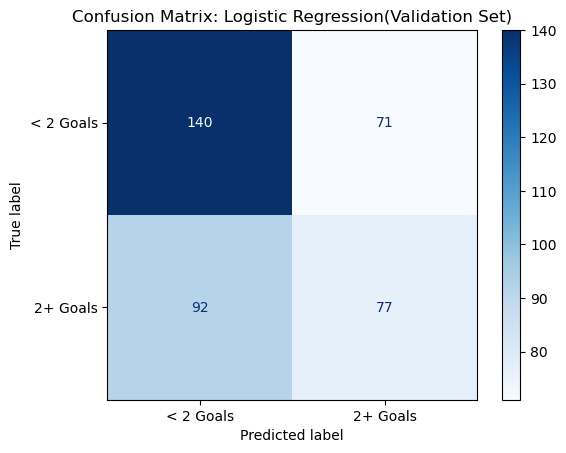

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


ConfusionMatrixDisplay.from_predictions(
    y_val, 
    lr_val_preds, 
    display_labels=["< 2 Goals", "2+ Goals"],
    cmap="Blues")

plt.title("Confusion Matrix: Logistic Regression(Validation Set)")
plt.show()

In [18]:
# Validation Conclusion: 
# It achieved an Accuracy of 0.571, F1 Score of 0.486, and ROC-AUC of 0.610.

# The ROC-AUC is slightly lower than the cross-validation score (0.633) but remains 
# well above the random baseline (0.500). This confirms the model generalises reasonably 
# well to unseen future data without catastrophic overfitting.

# The confusion matrix shows the model is conservative. It correctly identifies low scoring 
# games (140 True Negatives) but struggles to predict high-scoring games (92 False Negatives). 
# Because the majority class is < 2 goals, the model defaults to predicting low scores when uncertain. 

# While Logistic Regression remains the best model tested, predicting exact goal thresholds in 
# football is inherently difficult due to match randomness and the limitations of rolling averages.

In [19]:
model_rf = make_pipeline(                    
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=10, random_state=42))

model_rf.fit(X_train, y_train)

rf_val_probs = model_rf.predict_proba(X_val)[:, 1]   # Predict on the unseen validation data (2024/25 season)
rf_val_preds = (rf_val_probs >= 0.5).astype(int)

print("--- RANDOM FOREST VALIDATION SET RESULTS (2024/25) ---")
print(f"Accuracy: {accuracy_score(y_val, rf_val_preds):.3f}")
print(f"F1 Score: {f1_score(y_val, rf_val_preds):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_val, rf_val_probs):.3f}")

--- RANDOM FOREST VALIDATION SET RESULTS (2024/25) ---
Accuracy: 0.571
F1 Score: 0.489
ROC-AUC:  0.589


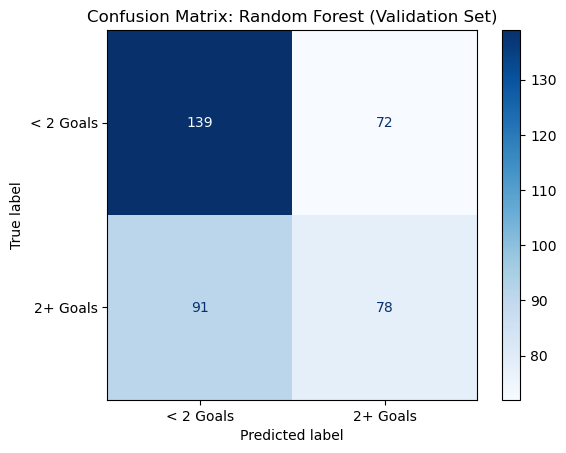

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_val_preds,
    display_labels=["< 2 Goals", "2+ Goals"],
    cmap="Blues")

plt.title("Confusion Matrix: Random Forest (Validation Set)")
plt.show()

In [21]:
model_knn = make_pipeline(                     
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=21, weights="uniform", p=1))

model_knn.fit(X_train, y_train)

knn_val_probs = model_knn.predict_proba(X_val)[:, 1]   # Predict on the unseen validation data (2024/25 season)
knn_val_preds = (knn_val_probs >= 0.5).astype(int)

print("--- K-NN VALIDATION SET RESULTS (2024/25) ---")
print(f"Accuracy: {accuracy_score(y_val, knn_val_preds):.3f}")
print(f"F1 Score: {f1_score(y_val, knn_val_preds):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_val, knn_val_probs):.3f}")

--- K-NN VALIDATION SET RESULTS (2024/25) ---
Accuracy: 0.555
F1 Score: 0.513
ROC-AUC:  0.567


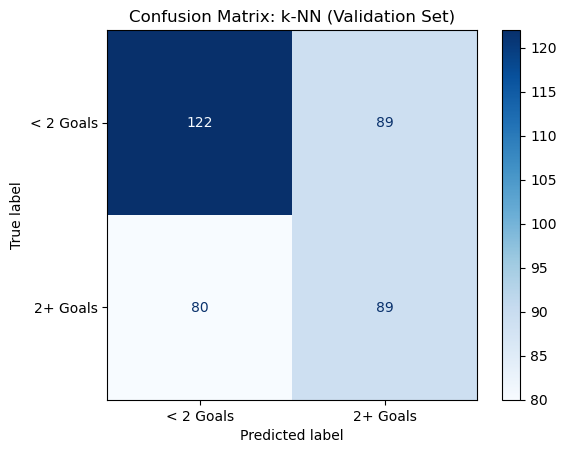

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    knn_val_preds,
    display_labels=["< 2 Goals", "2+ Goals"],
    cmap="Blues")

plt.title("Confusion Matrix: k-NN (Validation Set)")
plt.show()

In [23]:
model_gb = make_pipeline(                      
    SimpleImputer(strategy="median"),
    GradientBoostingClassifier(n_estimators=200, learning_rate=0.01, max_depth=1,
                               subsample=0.8, random_state=42))

model_gb.fit(X_train, y_train)

gb_val_probs = model_gb.predict_proba(X_val)[:, 1]   # Predict on the unseen validation data (2024/25 season)
gb_val_preds = (gb_val_probs >= 0.5).astype(int)

print("--- GRADIENT BOOSTING VALIDATION SET RESULTS (2024/25) ---")
print(f"Accuracy: {accuracy_score(y_val, gb_val_preds):.3f}")
print(f"F1 Score: {f1_score(y_val, gb_val_preds):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_val, gb_val_probs):.3f}")

--- GRADIENT BOOSTING VALIDATION SET RESULTS (2024/25) ---
Accuracy: 0.579
F1 Score: 0.433
ROC-AUC:  0.579


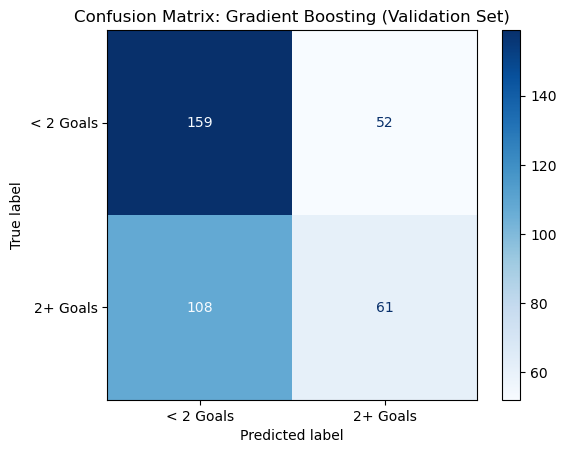

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    gb_val_preds,
    display_labels=["< 2 Goals", "2+ Goals"],
    cmap="Blues")

plt.title("Confusion Matrix: Gradient Boosting (Validation Set)")
plt.show()

In [25]:
# Gradient Boosting Validation Conclusion:
# The tuned Gradient Boosting achieved an Accuracy of 0.579, F1 Score of 0.433 and ROC-AUC of 0.579 on the
# validation season, a clear drop from its CV ROC-AUC of 0.632 and below Logistic Regression (0.610).
# The settings were chosen as the best of 27 combinations on the training folds, so the CV score was likely
# optimistic, and the validation season is small and noisy.

# Decision: Logistic Regression remains the preferred model, as its score was much more stable between
# cross-validation and validation.

#  Since Logistic Regression is still the preferred model, lets conduct an error analysis to see where the 
# model performs poorly.

In [26]:
err = validation[["MatchID", "Date", "Team", "Opponent"] + features_5].copy()
err["Goals"] = validation["MatchID"].map(df_home.set_index("MatchID")["Goals"])
err["actual"] = y_val.values
err["pred"] = lr_val_preds
err["correct"] = err["pred"] == err["actual"]

def slice_table(col):
    return (err.groupby(col, observed=True)
               .agg(matches=("actual", "size"), actual_2plus=("actual", "mean"),
                    predicted_2plus=("pred", "mean"), accuracy=("correct", "mean")).round(3))


# Home team's recent scoring form
err["attack_form"] = pd.qcut(err["Goals_avg5"], 3, labels=["low", "mid", "high"])
display(slice_table("attack_form"))

# How many goals the opponent has been conceding
err["opp_defence"] = pd.qcut(err["Opp_GoalsConceded_avg5"], 3, labels=["concedes few", "mid", "concedes many"])
display(slice_table("opp_defence"))

# The biggest misses (scored a lot, predicted fewer than 2)
cols = ["Date", "Team", "Opponent", "Goals", "Goals_avg5", "Opp_GoalsConceded_avg5"]
display(err[(err.pred == 0) & (err.actual == 1)].sort_values("Goals", ascending=False)[cols].head(5).round(2))

,matches,actual_2plus,predicted_2plus,accuracy
attack_form,,,,
low,142,0.387,0.162,0.620
mid,125,0.456,0.368,0.496
high,112,0.509,0.696,0.598


,matches,actual_2plus,predicted_2plus,accuracy
opp_defence,,,,
concedes few,179,0.397,0.285,0.609
mid,82,0.463,0.427,0.573
concedes many,118,0.500,0.517,0.508


,Date,Team,Opponent,Goals,Goals_avg5,Opp_GoalsConceded_avg5
1474,2025-02-01,Nott'm Forest,Brighton,7,1.6,1.2
1193,2025-04-12,Man City,Crystal Palace,5,2.2,0.2
68,2025-02-02,Arsenal,Man City,5,1.4,1.2
1383,2025-04-16,Newcastle,Crystal Palace,5,2.4,1.2
683,2025-05-20,Crystal Palace,Wolves,4,1.6,0.6


In [27]:
# Lets try adding the teams goal difference and see can we improve roc-auc
df_all = df.sort_values(["Team", "Date"]).reset_index(drop=True)
df_all["Conceded"] = df_all.groupby("MatchID")["Goals"].transform("sum") - df_all["Goals"]
df_all["GD"] = df_all["Goals"] - df_all["Conceded"]


def add_last10_gd(g):
    g = g.sort_values("Date").copy()
    g["GD_avg10"] = g["GD"].shift(1).rolling(10, min_periods=3).mean()
    return g

df_all = (df_all.groupby("Team", group_keys=False)
          .apply(add_last10_gd)
          .reset_index(drop=True))



gd_home = df_all[df_all["HomeAway"] == "Home"].set_index("MatchID")["GD_avg10"]
gd_away = df_all[df_all["HomeAway"] == "Away"].set_index("MatchID")["GD_avg10"]

df_model["Strength_diff"] = df_model["MatchID"].map(gd_home) - df_model["MatchID"].map(gd_away)

In [28]:
train = df_model[df_model["Date"] < train_end]
validation = df_model[(df_model["Date"] >= train_end) & (df_model["Date"] < val_end)]
test = df_model[df_model["Date"] >= val_end]

features_6 = features_5 + ["Strength_diff"]

# Comparing the difference when the extra feature is added
cv_results_6feat = run_cv(features_6)
print("5 features (current)")
display(cv_results_5feat)
print("6 features (+ team strength difference)")
display(cv_results_6feat)

5 features (current)


,Accuracy,F1,ROC-AUC mean,ROC-AUC std,Fit time (s),Predict time (s)
Model,,,,,,
Dummy,0.519,0.000,0.500,0.000,0.012,0.026
Logistic Regression,0.600,0.548,0.633,0.044,0.024,0.023
Random Forest,0.575,0.536,0.602,0.045,1.661,0.486
k-NN,0.568,0.524,0.575,0.033,0.017,0.034
Gradient Boosting,0.552,0.509,0.582,0.042,0.765,0.028


6 features (+ team strength difference)


,Accuracy,F1,ROC-AUC mean,ROC-AUC std,Fit time (s),Predict time (s)
Model,,,,,,
Dummy,0.519,0.000,0.500,0.000,0.008,0.018
Logistic Regression,0.603,0.552,0.655,0.034,0.022,0.021
Random Forest,0.586,0.542,0.624,0.043,1.530,0.441
k-NN,0.573,0.522,0.592,0.024,0.016,0.025
Gradient Boosting,0.567,0.521,0.599,0.037,0.672,0.025


In [29]:
# Team Strength Feature Conclusion:
# Adding the strength difference (home team's average goal difference over its last 10 matches minus the
# opponent's) improved ROC-AUC for all four models. Logistic Regression rose from 0.633 to 0.655, Random Forest
# from 0.602 to 0.624, Gradient Boosting from 0.582 to 0.599 and k-NN from 0.575 to 0.592. Accuracy and F1
# changed very little. The gains are small relative to the fold standard deviations (0.02-0.04), so the size of
# the improvement is uncertain, but its consistency across models suggests the feature adds real information.

# Logistic Regression remains the best model. Let's now compare logistic regression and random forset using the validation set.

In [30]:
train = train.sort_values(["Date", "Time"])

X_train, y_train = train[features_6], train["Target"]
X_val,   y_val   = validation[features_6], validation["Target"]


model_lr6 = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000))
model_lr6.fit(X_train, y_train)

lr6_val_probs = model_lr6.predict_proba(X_val)[:, 1]
lr6_val_preds = (lr6_val_probs >= 0.5).astype(int)

model_rf6 = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=500, max_depth=4, min_samples_leaf=10, random_state=42))
model_rf6.fit(X_train, y_train)

rf6_val_probs = model_rf6.predict_proba(X_val)[:, 1]
rf6_val_preds = (rf6_val_probs >= 0.5).astype(int)

In [31]:
val_results_6 = pd.DataFrame({
    "Accuracy": [accuracy_score(y_val, lr6_val_preds), accuracy_score(y_val, rf6_val_preds)],
    "F1":       [f1_score(y_val, lr6_val_preds),       f1_score(y_val, rf6_val_preds)],
    "ROC-AUC":  [roc_auc_score(y_val, lr6_val_probs),  roc_auc_score(y_val, rf6_val_probs)]},
    index=["Logistic Regression", "Random Forest"]).round(3)

print("--- VALIDATION RESULTS (2024/25), 6 features ---")
display(val_results_6)

--- VALIDATION RESULTS (2024/25), 6 features ---


,Accuracy,F1,ROC-AUC
Logistic Regression,0.613,0.553,0.641
Random Forest,0.618,0.570,0.637


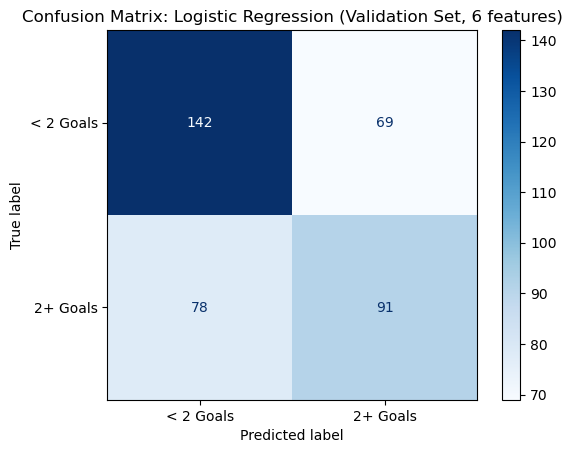

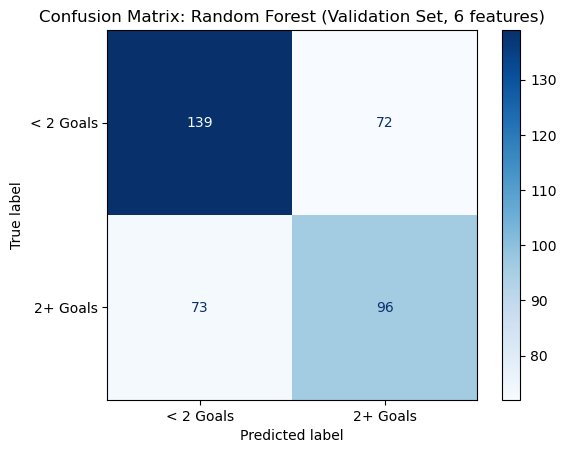

In [32]:
# Logistic Regression (6 features)
ConfusionMatrixDisplay.from_predictions(
    y_val,
    lr6_val_preds,
    display_labels=["< 2 Goals", "2+ Goals"],
    cmap="Blues")
plt.title("Confusion Matrix: Logistic Regression (Validation Set, 6 features)")
plt.show()

# Random Forest (6 features)
ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf6_val_preds,
    display_labels=["< 2 Goals", "2+ Goals"],
    cmap="Blues")
plt.title("Confusion Matrix: Random Forest (Validation Set, 6 features)")
plt.show()

In [33]:
# Validation Conclusion (6 features):
# Adding the strength difference improved Logistic Regression on the 2024/25 validation season: accuracy 0.571 to 0.613,
# F1 0.486 to 0.553 and ROC-AUC 0.610 to 0.641. The confusion matrix shows fewer missed high-scoring games
# (false negatives fell from 92 to 78), so the model is less conservative. Random Forest improved by a similar amount
# (ROC-AUC 0.589 to 0.637).

# The two models are now almost level (ROC-AUC 0.641 vs 0.637, Random Forest slightly ahead on accuracy and F1), so
# the validation season does not clearly separate them. Logistic Regression is kept as the preferred model because it
# is simpler, faster and easier to interpret, but the gap in performance is within noise.

In [34]:
train_s = train.sort_values(["Date", "Time"])
X_train, y_train = train_s[features_6], train_s["Target"]

# Redefine the test set using the six features
X_test, y_test = test[features_6], test["Target"]

lr6_test_probs = model_lr6.predict_proba(X_test)[:, 1]
lr6_test_preds = (lr6_test_probs >= 0.5).astype(int)

rf6_test_probs = model_rf6.predict_proba(X_test)[:, 1]
rf6_test_preds = (rf6_test_probs >= 0.5).astype(int)

dummy = make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="prior"))
dummy.fit(X_train, y_train)
dummy_test_probs = dummy.predict_proba(X_test)[:, 1]
dummy_test_preds = (dummy_test_probs >= 0.5).astype(int)

test_results_6 = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, dummy_test_preds), accuracy_score(y_test, lr6_test_preds), accuracy_score(y_test, rf6_test_preds)],
    "F1":       [f1_score(y_test, dummy_test_preds),       f1_score(y_test, lr6_test_preds),       f1_score(y_test, rf6_test_preds)],
    "ROC-AUC":  [roc_auc_score(y_test, dummy_test_probs),  roc_auc_score(y_test, lr6_test_probs),  roc_auc_score(y_test, rf6_test_probs)]},
    index=["Dummy", "Logistic Regression", "Random Forest"]).round(3)

print("--- TEST RESULTS (2025/26), 6 features ---")
display(test_results_6)

--- TEST RESULTS (2025/26), 6 features ---


,Accuracy,F1,ROC-AUC
Dummy,0.516,0.000,0.500
Logistic Regression,0.561,0.473,0.577
Random Forest,0.545,0.447,0.582


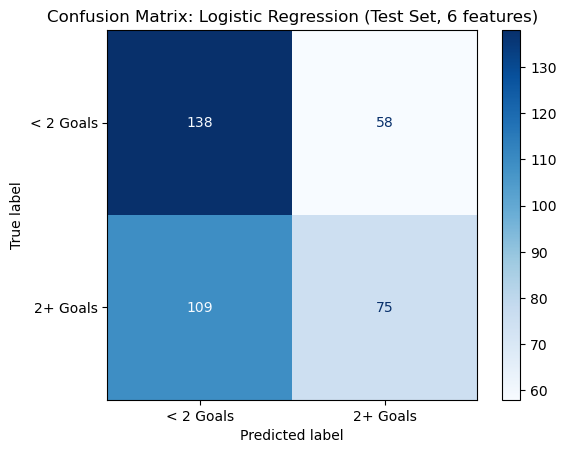

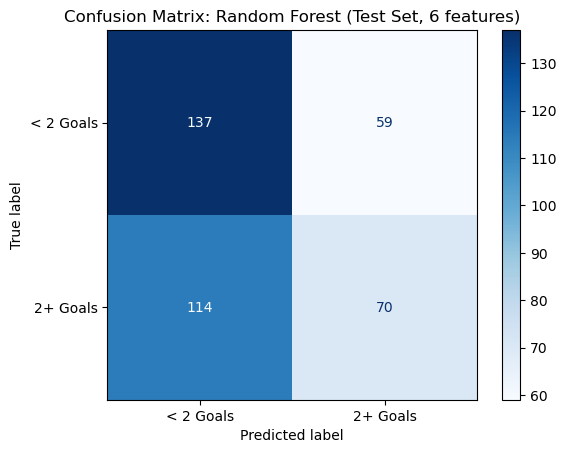

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_test, lr6_test_preds,
    display_labels=["< 2 Goals", "2+ Goals"], cmap="Blues")
plt.title("Confusion Matrix: Logistic Regression (Test Set, 6 features)")
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, rf6_test_preds,
    display_labels=["< 2 Goals", "2+ Goals"], cmap="Blues")
plt.title("Confusion Matrix: Random Forest (Test Set, 6 features)")
plt.show()

In [36]:
# Test Set Conclusion:
# On the unseen 2025/26 season, Logistic Regression achieved an Accuracy of 0.561, F1 of 0.473 and
# ROC-AUC of 0.577, and Random Forest achieved 0.545, 0.447 and 0.582. Both beat the dummy baseline
# (ROC-AUC 0.500), so the features contain some real predictive signal, but the signal is weak.

# ROC-AUC was lower than in cross-validation (0.655) and on the validation season (0.641). This is
# likely due to a combination of chance (a single season is small and football results are noisy),
# and the fact that the features and model were chosen using the earlier results, which makes those
# scores somewhat optimistic. The 0.577 test score is the most realistic estimate of performance.

# The two models are effectively tied (0.577 vs 0.582), so the test set does not separate them.
# Logistic Regression is kept as the final model, as decided before testing, because it is simpler,
# faster and easier to interpret. Overall, the model is better than guessing but not reliable enough
# to predict individual matches, and should not be used for decisions such as betting.